# Дискриминантный анализ в Python

**Дисциплина:** Введение в анализ больших данных

**LDA (линейный дискриминантный анализ)** — классификация с учителем: по признакам отнести объект к одному из **заранее известных** классов.

Отличие от кластеризации: метки классов даны при обучении.

Инструменты: `sklearn.discriminant_analysis.LinearDiscriminantAnalysis`, PCA, MANOVA.

Демо: **penguins** (вид по морфометрии).

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics import classification_report, accuracy_score
from statsmodels.multivariate.manova import MANOVA


plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)

---
## 1. Данные


In [9]:
df = pd.read_csv('INZc.csv', sep=';', decimal=',', encoding="cp1251")

features = ['Эйфаузиевые', 'Амфиподы', 'Копеподы', 'Декаподы', 'Птероподы',
            'Ойкоплевры', 'Сагиты', 'Нектон', 'ИНЖ', 'Размер']
X = df[features]
y = df['Район']

In [13]:
print('== Классы ==')
print(y.value_counts())

print('\n== описательная статистика ==')
print(X.describe().round(1))

== Классы ==
Район
Сахалин                 6
БерМоре                 6
Залив_Петра_Великого    5
Name: count, dtype: int64

== описательная статистика ==
       Эйфаузиевые  Амфиподы  Копеподы  Декаподы  Птероподы  Ойкоплевры  \
count         17.0      17.0      17.0      17.0       17.0        17.0   
mean          28.6      15.4       9.7       4.7        8.0         0.9   
std           23.5      15.7      10.7      13.6        7.2         2.6   
min            0.1       0.0       0.0       0.0        0.0         0.0   
25%           10.0       3.1       1.9       0.0        0.0         0.0   
50%           17.6      12.9       7.1       0.0        7.0         0.0   
75%           45.0      20.2      12.6       0.5       12.2         0.0   
max           87.0      61.2      38.4      54.5       23.0        10.0   

       Сагиты  Нектон    ИНЖ  Размер  
count    17.0    17.0   17.0    17.0  
mean      2.6    29.2  105.9    41.7  
std       6.2    29.0   66.7    11.0  
min       0.0 

### Описательная стаитисктика

Классы сбалансированы, что не допускает смещения в сторону доминирующего класса.

Также судя по разным средним значениям фичей - нам понадобится стандартизация, иначе будет искусственная доминация по коэффициенту признака.

`Ойкоплевры` имеют как будто сильную доминацию, поскольку 75% данных = 0.0


---
## 2. PCA (разведка)

PCA ищет направления **максимальной дисперсии** (не обязательно разделения классов).


In [17]:
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

pca = PCA()
scores = pca.fit_transform(Xs)

print("Доля дисперсии, объясняемая каждой компонентой:", np.round(pca.explained_variance_ratio_, 3))
print("Накопленная доля дисперсии:                    ", np.round(np.cumsum(pca.explained_variance_ratio_), 3))

print("\nВеса признаков в главных компонентах (Loadings):")
loadings_df = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f"PC{i+1}" for i in range(len(features))]
).round(3)
print(loadings_df)


Доля дисперсии, объясняемая каждой компонентой: [0.305 0.192 0.149 0.142 0.087 0.077 0.03  0.016 0.002 0.   ]
Накопленная доля дисперсии:                     [0.305 0.497 0.645 0.787 0.875 0.952 0.982 0.998 1.    1.   ]

Веса признаков в главных компонентах (Loadings):
               PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9  \
Эйфаузиевые  0.344  0.006  0.287  0.512 -0.374  0.098 -0.169 -0.191 -0.223   
Амфиподы     0.398 -0.026 -0.269 -0.399  0.043 -0.340  0.453 -0.411 -0.097   
Копеподы     0.059 -0.367 -0.087 -0.414 -0.119  0.772  0.040  0.125 -0.037   
Декаподы    -0.140 -0.158  0.499 -0.470 -0.198 -0.428 -0.194  0.358  0.046   
Птероподы   -0.059 -0.010  0.602  0.065  0.669  0.181  0.273 -0.194  0.113   
Ойкоплевры   0.022  0.642  0.114 -0.017 -0.236  0.156  0.553  0.429 -0.047   
Сагиты       0.036  0.587 -0.083 -0.318  0.295  0.124 -0.545 -0.106 -0.333   
Нектон      -0.448  0.025 -0.431  0.221  0.193 -0.064  0.015  0.175  0.269   
ИНЖ          0.441 -0.238 -0

### Выводы
**loadings**:
Нагрузка - это влияние признаков на компоненты и измеряется от 1 до -1


**Доля дисперсии для каждой компоненты:**
Уже первые 2 компоненты объясняет 50% дисперсии, а 4 компоненты - 79%

Эвристические правила:
1. Критерий Кайзера:
> Оставляем только те компоненты, у которых собственная доля дисперсии больше среднего (т.е. > 1/число_признаков = 1/10 = 0.1)
2. Доля объяснённой дисперсии:
> Разумно выделить накопленной доли дисперсии 80-90% с учётом Критерия Кайзера

По эвристическим правилам получается, что у нас всего 4 компоненты, до PC4 включительно.

Также 2 первые компоненты можем использовать для 2D представления без относительно сильных потерь.


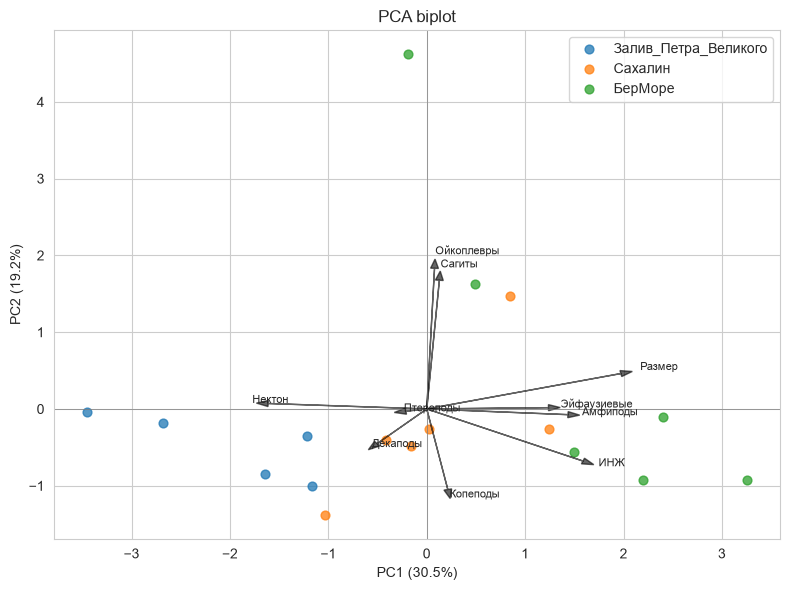

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))
for sp in y.unique():
    m = y == sp
    ax.scatter(scores[m, 0], scores[m, 1], label=sp, s=40, alpha=0.75)
load = pca.components_.T * np.sqrt(pca.explained_variance_)
for i, name in enumerate(features):
    ax.arrow(0, 0, load[i, 0]*2, load[i, 1]*2, color="k", alpha=0.6, head_width=0.08)
    ax.text(load[i, 0]*2.2, load[i, 1]*2.2, name, fontsize=8)
ax.set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.1f}%)")
ax.legend(); ax.set_title("PCA biplot")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
plt.tight_layout(); plt.show()


### Вывод

График отображает степень влияния визуально на PC1 и PC2, так как у PC1 больше сконцентрировано данных, то и стрелки длиннее

Классы визуально начинают группироваться даже без LDA. `БерМоре` и `Залив_Петра_Великого` разделяются в основном по оси PC1. Это значит, что LDA должен сработать хорошо.

---
## 3. LDA: обучение и прогноз

Train / test → `LDA().fit` → `predict` → confusion matrix / accuracy.


In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.36, random_state=7, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))


lda.fit(X_train, y_train)
y_pred = lda.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nConfusion matrix:")
print(pd.crosstab(y_pred, y_test, rownames=["Predicted"], colnames=["Actual"]))
print("\n", classification_report(y_test, y_pred, digits=3))


# lda_cv = LDA()
# y_pred = cross_val_predict(lda_cv, X, y, cv=5)
# print(classification_report(y, y_pred, zero_division=0))

Train: 10 Test: 7
Accuracy: 0.714

Confusion matrix:
Actual                БерМоре  Залив_Петра_Великого  Сахалин
Predicted                                                   
БерМоре                     1                     0        0
Залив_Петра_Великого        0                     2        1
Сахалин                     1                     0        2

                       precision    recall  f1-score   support

             БерМоре      1.000     0.500     0.667         2
Залив_Петра_Великого      0.667     1.000     0.800         2
             Сахалин      0.667     0.667     0.667         3

            accuracy                          0.714         7
           macro avg      0.778     0.722     0.711         7
        weighted avg      0.762     0.714     0.705         7



### Вывод

# accuracy != precision

recall - минимизация ложных пропусков

precision - минимизация ложных срабатываний


In [72]:
print("Классы:", lda.classes_)
print("Приоры:", np.round(lda.priors_, 3))
print("\nСредние по классам:")
print(pd.DataFrame(lda.means_, index=lda.classes_, columns=features).round(1))
print("\nКоэффициенты LD:")
print(pd.DataFrame(
    lda.scalings_, index=features,
    columns=[f"LD{i+1}" for i in range(lda.scalings_.shape[1])]
).round(3))


Классы: ['БерМоре' 'Залив_Петра_Великого' 'Сахалин']
Приоры: [0.4 0.3 0.3]

Средние по классам:
                      Эйфаузиевые  Амфиподы  Копеподы  Декаподы  Птероподы  \
БерМоре                      21.8      32.2      10.9       1.3        4.5   
Залив_Петра_Великого         13.8       8.9      11.4      24.4        9.9   
Сахалин                      54.4      11.7       2.4       0.2       13.6   

                      Ойкоплевры  Сагиты  Нектон    ИНЖ  Размер  
БерМоре                      2.5     9.5    16.0  133.2    53.0  
Залив_Петра_Великого         0.0     0.7    30.8   75.3    32.3  
Сахалин                      1.7     0.0    15.5  107.7    43.3  

Коэффициенты LD:
               LD1    LD2
Эйфаузиевые  0.027  0.049
Амфиподы    -0.054 -0.007
Копеподы    -0.027  0.005
Декаподы     0.014 -0.070
Птероподы    0.180  0.280
Ойкоплевры   0.081  0.111
Сагиты      -0.260 -0.030
Нектон       0.017 -0.020
ИНЖ          0.006  0.005
Размер      -0.278  0.080


### Вывод

**Классы и приоритеты:**

Модель будет склонна при сомнениях относить к наивысшему приоритету класса.

**Коэффициенты LD:**

ТОП по LD1: Птероподы, Сагиты, Размер

ТОП по LD2: Птероподы, Ойкоплевры, Размер



### Проекция на LD1–LD2


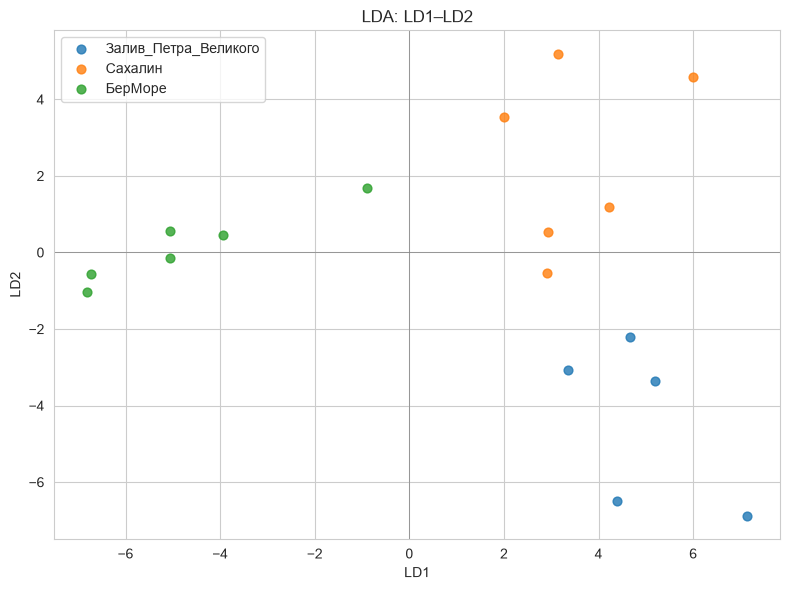

In [73]:
X_ld = lda.transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
for sp in y.unique():
    m = y == sp
    ax.scatter(X_ld[m, 0], X_ld[m, 1], label=sp, s=40, alpha=0.8)
ax.set_xlabel("LD1"); ax.set_ylabel("LD2")
ax.legend(); ax.set_title("LDA: LD1–LD2")
ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
plt.tight_layout(); plt.show()


### Разделимость классов: MANOVA (Wilks)

H0: векторы средних по классам совпадают.


In [76]:
df_m = X.copy()
df_m["Район"] = y

formula = " + ".join(features) + " ~ Район"
print(MANOVA.from_formula(formula, data=df_m).mv_test())


                    Multivariate linear model
                                                                 
-----------------------------------------------------------------
       Intercept          Value    Num DF Den DF  F Value  Pr > F
-----------------------------------------------------------------
          Wilks' lambda    0.0001 10.0000 5.0000 4468.1289 0.0000
         Pillai's trace    0.9999 10.0000 5.0000 4468.1289 0.0000
 Hotelling-Lawley trace 8936.2578 10.0000 5.0000 4468.1289 0.0000
    Roy's greatest root 8936.2578 10.0000 5.0000 4468.1289 0.0000
-----------------------------------------------------------------
                                                                 
-----------------------------------------------------------------
            Район           Value   Num DF  Den DF F Value Pr > F
-----------------------------------------------------------------
             Wilks' lambda  0.0050 20.0000 10.0000  6.5462 0.0021
            Pillai's trace  1.

### Вывод

$H_0$: Векторы средних значений всех признаков одинаковы для всех классов

Смотрим только на Район, потому что Intercept - техническая статистика

Можно взять за основу показатель - `лямбда Уилка`:
> val = 0.005 (Мы смотрим на близость к 0), значит классы отлично различаются

А вообще, выборка маленькая


### Как описать результаты

1. Accuracy и confusion matrix на **test**.  
2. Какие классы путаются чаще.  
3. MANOVA: p < 0.05 → классы различаются в пространстве признаков.  
4. Интерпретация коэффициентов LD (scalings).

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| LDA | `LDA().fit(X_train, y_train)` |
| Класс | `lda.predict(X)` |
| Вероятности | `lda.predict_proba(X)` |
| Координаты LD | `lda.transform(X)` |
| Confusion | `pd.crosstab` / metrics |
| PCA | `PCA().fit_transform(StandardScaler().fit_transform(X))` |
| MANOVA | `MANOVA.from_formula("y1+y2 ~ class", data=df)` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и выполните LDA **самостоятельно**.  
2. Помните: PCA максимизирует дисперсию, LDA — **разделимость классов**.

Удачи!
